# Spark Sandbox — Getting Started

## Service endpoints

| Service | URL | Notes |
|---|---|---|
| Spark Master UI | http://localhost:8080 | Cluster overview |
| Spark App UI | http://localhost:4040 | Active while a job runs |
| Kafka UI | http://localhost:8090 | Topics, messages, consumer groups |
| JupyterLab | http://localhost:8888 | token: `spark123` |
| PostgreSQL | `localhost:5432` | db: sandbox, user: spark, pwd: spark123 |

## Sections
1. SparkSession setup
2. Batch pipeline → PostgreSQL
3. DuckDB analytics on Parquet
4. Kafka producer
5. Spark Structured Streaming from Kafka

---
## 1 · SparkSession

In [1]:
import os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

SPARK_MASTER  = os.getenv('SPARK_MASTER',            'spark://spark-master:7077')
KAFKA_SERVERS = os.getenv('KAFKA_BOOTSTRAP_SERVERS', 'kafka:29092')
PG_URL        = f"jdbc:postgresql://{os.getenv('POSTGRES_HOST','postgres')}:5432/{os.getenv('POSTGRES_DB','sandbox')}"
PG_PROPS      = {'user': os.getenv('POSTGRES_USER','spark'), 'password': os.getenv('POSTGRES_PASSWORD','spark123'), 'driver': 'org.postgresql.Driver'}

spark = (
    SparkSession.builder
    .appName('sandbox')
    .master(SPARK_MASTER)
    .getOrCreate()
)

spark.sparkContext.setLogLevel('WARN')
print(f'Spark {spark.version} — master: {spark.sparkContext.master}')

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/07/01 20:10:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.3 — master: spark://spark-master:7077


---
## 2 · Batch pipeline

Pattern: **generate → transform → write PostgreSQL + Parquet**

In [3]:
# Read existing tables from PostgreSQL
users = spark.read.jdbc(PG_URL, 'users', properties=PG_PROPS)
txns  = spark.read.jdbc(PG_URL, 'transactions', properties=PG_PROPS)

users.printSchema()
txns.show(10)

root
 |-- id: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- email: string (nullable = true)
 |-- country: string (nullable = true)
 |-- created_at: timestamp (nullable = true)

+---+-------+------+-----------+---------+--------------------+
| id|user_id|amount|   category|   status|          created_at|
+---+-------+------+-----------+---------+--------------------+
|  1|      1|150.00|electronics|completed|2026-06-17 20:18:...|
|  2|      1| 25.50|       food|completed|2026-06-17 20:18:...|
|  3|      2| 89.99|   clothing|completed|2026-06-17 20:18:...|
|  4|      3|200.00|electronics|completed|2026-06-17 20:18:...|
|  5|      2| 12.00|       food|completed|2026-06-17 20:18:...|
|  6|      4|340.00|     travel|completed|2026-06-17 20:18:...|
|  7|      5| 55.00|   clothing|  pending|2026-06-17 20:18:...|
|  8|      1| 18.75|       food|completed|2026-06-17 20:18:...|
|  9|      3| 99.00|electronics| refunded|2026-06-17 20:18:...|
| 10|      4| 30.00|       food|co

In [4]:
from faker import Faker
import random

# Generate synthetic transactions
fake   = Faker()
CATS   = ['electronics', 'food', 'clothing', 'travel', 'health']
STATUS = ['completed', 'pending', 'refunded']

rows = [
    (random.randint(1, 5), round(random.uniform(5, 500), 2),
     random.choice(CATS), random.choice(STATUS),
     fake.date_time_between('-30d', 'now'))
    for _ in range(200)
]

schema = StructType([
    StructField('user_id',    IntegerType()),
    StructField('amount',     DoubleType()),
    StructField('category',   StringType()),
    StructField('status',     StringType()),
    StructField('created_at', TimestampType()),
])

df = spark.createDataFrame(rows, schema)

# Enrich with user country
enriched = (
    df.join(users.select('id', 'country'), df.user_id == users.id)
      .drop('id')
      .withColumn('date', F.to_date('created_at'))
)

enriched.show(5)

+-------+------+--------+---------+--------------------+-------+----------+
|user_id|amount|category|   status|          created_at|country|      date|
+-------+------+--------+---------+--------------------+-------+----------+
|      1|252.87|clothing| refunded|2026-06-10 21:34:...|     US|2026-06-10|
|      1|391.43|  health|  pending|2026-07-01 00:41:...|     US|2026-07-01|
|      1|105.56|    food|completed|2026-06-24 01:33:...|     US|2026-06-24|
|      1| 238.2|  travel| refunded|2026-06-26 01:28:...|     US|2026-06-26|
|      1|120.15|    food|completed|2026-06-13 21:42:...|     US|2026-06-13|
+-------+------+--------+---------+--------------------+-------+----------+
only showing top 5 rows


In [5]:
# Daily category summary
summary = (
    enriched
    .filter(F.col('status') == 'completed')
    .groupBy('date', 'category')
    .agg(
        F.round(F.sum('amount'), 2).alias('total_amount'),
        F.count('*').alias('tx_count'),
    )
    .orderBy('date', 'category')
)

summary.show(10)

+----------+-----------+------------+--------+
|      date|   category|total_amount|tx_count|
+----------+-----------+------------+--------+
|2026-06-01|electronics|      389.92|       1|
|2026-06-02|electronics|      289.48|       2|
|2026-06-02|       food|       225.4|       1|
|2026-06-02|     health|      285.64|       1|
|2026-06-03|   clothing|      291.31|       1|
|2026-06-04|     health|       97.66|       1|
|2026-06-04|     travel|      546.84|       2|
|2026-06-05|     health|       87.19|       1|
|2026-06-06|electronics|      417.83|       1|
|2026-06-06|     health|      293.35|       1|
+----------+-----------+------------+--------+
only showing top 10 rows


In [6]:
# Write to PostgreSQL
summary.withColumnRenamed('date', 'summary_date') \
       .write.jdbc(PG_URL, 'daily_summary', mode='overwrite', properties=PG_PROPS)

# Write to Parquet (for DuckDB section)
enriched.write.mode('overwrite').parquet('/home/jupyter/data/output/transactions')

print('Done writing.')

Done writing.


---
## 3 · DuckDB analytics

DuckDB can query Parquet files directly — great for fast ad-hoc analytics after a Spark job.

In [7]:
import duckdb

con = duckdb.connect()  # in-memory

# Register the Parquet dataset written by Spark
con.execute("CREATE VIEW transactions AS SELECT * FROM read_parquet('/home/jupyter/data/output/transactions/**/*.parquet')")

con.execute('SELECT * FROM transactions LIMIT 5').df()

,user_id,amount,category,status,created_at,country,date
0,1,252.87,clothing,refunded,2026-06-10 21:34:49.531096,US,2026-06-10
1,1,391.43,health,pending,2026-07-01 00:41:35.948340,US,2026-07-01
2,1,105.56,food,completed,2026-06-24 01:33:50.763131,US,2026-06-24
3,1,238.20,travel,refunded,2026-06-26 01:28:10.587837,US,2026-06-26
4,1,120.15,food,completed,2026-06-13 21:42:19.543586,US,2026-06-13


In [8]:
# Revenue by country & category
result = con.execute("""
    SELECT
        country,
        category,
        ROUND(SUM(amount), 2)  AS total_revenue,
        COUNT(*)               AS tx_count,
        ROUND(AVG(amount), 2)  AS avg_amount
    FROM transactions
    WHERE status = 'completed'
    GROUP BY ALL
    ORDER BY total_revenue DESC
""").df()

result

,country,category,total_revenue,tx_count,avg_amount
0,US,health,1700.44,7,242.92
1,SG,electronics,1420.34,6,236.72
2,US,electronics,1348.91,4,337.23
3,US,travel,1328.59,5,265.72
4,DE,electronics,1200.33,4,300.08
5,UK,health,1122.37,4,280.59
6,DE,clothing,1058.18,5,211.64
7,MX,travel,1055.16,4,263.79
8,UK,travel,1011.59,3,337.20
9,DE,food,792.36,2,396.18


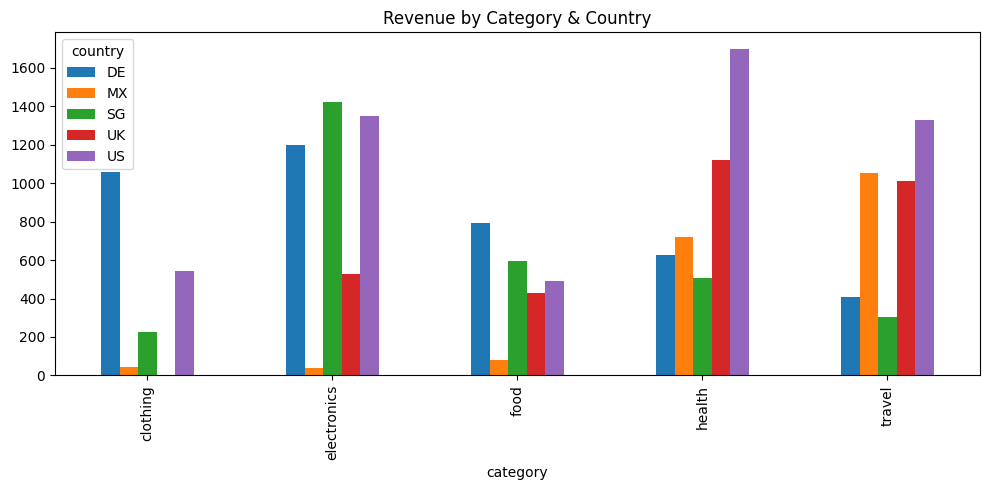

In [9]:
import matplotlib.pyplot as plt

pivot = result.pivot(index='category', columns='country', values='total_revenue').fillna(0)
pivot.plot(kind='bar', figsize=(10, 5), title='Revenue by Category & Country')
plt.tight_layout()
plt.show()

---
## 4 · Kafka producer

Send simulated events that the streaming job will consume.

In [19]:
import json, time, random, threading
from kafka import KafkaProducer
from faker import Faker
from datetime import datetime, timezone

fake = Faker()
CATS = ['electronics', 'food', 'clothing', 'travel', 'health']

producer = KafkaProducer(
    bootstrap_servers=KAFKA_SERVERS,
    value_serializer=lambda v: json.dumps(v).encode(),
)

def send_events(n=50, delay=0.2):
    for i in range(n):
        event = {
            'event_id':  fake.uuid4(),
            'user_id':   random.randint(1, 5),
            'amount':    round(random.uniform(5, 500), 2),
            'category':  random.choice(CATS),
            'ts':        datetime.now(timezone.utc).isoformat(),
        }
        producer.send('transactions', value=event)
        time.sleep(delay)
    producer.flush()
    print(f'Sent {n} events.')

# Send events in a background thread so the notebook stays responsive
t = threading.Thread(target=send_events, args=(100, 0.1), daemon=True)
t.start()
print('Producer started — check Kafka UI at http://localhost:8090')

Producer started — check Kafka UI at http://localhost:8090


---
## 5 · Spark Structured Streaming

Consume `transactions` topic, aggregate over a 1-minute tumbling window, write to console and PostgreSQL.

In [20]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, IntegerType, TimestampType

event_schema = StructType([
    StructField('event_id', StringType()),
    StructField('user_id',  IntegerType()),
    StructField('amount',   DoubleType()),
    StructField('category', StringType()),
    StructField('ts',       StringType()),
])

raw = (
    spark.readStream
    .format('kafka')
    .option('kafka.bootstrap.servers', KAFKA_SERVERS)
    .option('subscribe', 'transactions')
    .option('startingOffsets', 'earliest')
    .load()
)

events = (
    raw
    .select(F.from_json(F.col('value').cast('string'), event_schema).alias('e'))
    .select('e.*')
    .withColumn('event_time', F.to_timestamp('ts'))
)

events.printSchema()

root
 |-- event_id: string (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- amount: double (nullable = true)
 |-- category: string (nullable = true)
 |-- ts: string (nullable = true)
 |-- event_time: timestamp (nullable = true)



In [21]:
# 1-minute tumbling window aggregation with 10-second watermark
windowed = (
    events
    .withWatermark('event_time', '10 seconds')
    .groupBy(
        F.window('event_time', '1 minute'),
        'category',
    )
    .agg(
        F.round(F.sum('amount'), 2).alias('total_amount'),
        F.count('*').alias('tx_count'),
    )
    .select(
        F.col('window.start').alias('window_start'),
        F.col('window.end').alias('window_end'),
        'category',
        'total_amount',
        'tx_count',
    )
)

In [22]:
# Print to console — swap outputMode/sink for production use
query = (
    windowed.writeStream
    .outputMode('update')
    .format('console')
    .option('truncate', False)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/streaming_demo')
    .trigger(processingTime='15 seconds')
    .start()
)

print(f'Streaming query started: {query.id}')
print('Results appear in the Spark UI → Structured Streaming tab.')
print('Run query.stop() to halt.')

Streaming query started: e2705ea6-7802-48f7-a060-80cf82cf1271
Results appear in the Spark UI → Structured Streaming tab.
Run query.stop() to halt.


26/07/01 20:21:43 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/07/01 20:21:43 WARN StreamingQueryManager: Stopping existing streaming query [id=e2705ea6-7802-48f7-a060-80cf82cf1271, runId=7f74b247-6f34-44bd-ae50-058bb49423f8], as a new run is being started.
26/07/01 20:21:43 WARN DAGScheduler: Failed to cancel job group 7f74b247-6f34-44bd-ae50-058bb49423f8. Cannot find active jobs for it.
26/07/01 20:21:44 WARN DAGScheduler: Failed to cancel job group 7f74b247-6f34-44bd-ae50-058bb49423f8. Cannot find active jobs for it.


-------------------------------------------
Batch: 3
-------------------------------------------
+-------------------+-------------------+-----------+------------+--------+
|window_start       |window_end         |category   |total_amount|tx_count|
+-------------------+-------------------+-----------+------------+--------+
|2026-07-01 20:21:00|2026-07-01 20:22:00|health     |1714.69     |7       |
|2026-07-01 20:21:00|2026-07-01 20:22:00|travel     |1652.5      |7       |
|2026-07-01 20:21:00|2026-07-01 20:22:00|electronics|724.55      |3       |
|2026-07-01 20:21:00|2026-07-01 20:22:00|clothing   |1683.73     |6       |
|2026-07-01 20:21:00|2026-07-01 20:22:00|food       |1485.62     |5       |
+-------------------+-------------------+-----------+------------+--------+

-------------------------------------------
Batch: 4
-------------------------------------------
+-------------------+-------------------+-----------+------------+--------+
|window_start       |window_end         |cate

In [23]:
# Stop when done
query.stop()
print('Stream stopped.')

Stream stopped.


26/07/01 20:22:24 WARN DAGScheduler: Failed to cancel job group ba20376c-f136-44e4-8dc7-3742dbb8f8e8. Cannot find active jobs for it.
26/07/01 20:22:24 WARN DAGScheduler: Failed to cancel job group ba20376c-f136-44e4-8dc7-3742dbb8f8e8. Cannot find active jobs for it.
